# Báo cáo CLDL và kết quả mô hình
Notebook này được sắp xếp phần trình bày theo luồng demo:

1. **KPI tổng quan:** 6 khía cạnh chất lượng dữ liệu + M1.
2. **Chi tiết sau đo:** kết quả theo khía cạnh và theo cột/quy tắc.
3. **Trước / sau can thiệp:** Train thô → SMOTENC và Random Oversampling.
4. **Thí nghiệm phụ (tách riêng):** điền khuyết và làm giàu, chỉ hiện khi bạn cấu hình file tương ứng (không dùng).
5. **Mô hình + output + giải thích nghiệp vụ.**

Các quy ước đo được giữ lại: Completeness kiểm tra khác rỗng/giá trị số hữu hạn; Validity dùng miền cố định `age [18,100]`, `physical_health_days [0,30]`, `mental_health_days [0,30]` và kiểm tra số nguyên; Uniqueness dùng `keep='first'` (còn `keep=False` chỉ đối chiếu); Consistency đo trên các bản ghi khác nhau; Timeliness dùng công thức Pipino đang có; Accuracy là **độ trung thực phân phối so với Test theo từng lớp**, không phải độ chính xác dự đoán của mô hình.


## 1. Cấu hình dữ liệu và báo cáo

Hai nhánh **điền khuyết** và **làm giàu** đang là thí nghiệm phụ; để `None` nếu chưa quyết định đưa vào báo cáo.


In [ ]:
# =====================================================================
# BƯỚC 1 — CẤU HÌNH
# =====================================================================
import os, re, json, warnings
from dataclasses import dataclass
from typing import Callable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# --- Bộ dữ liệu nền và tham chiếu: dùng chung cho mọi phiên bản ---
X_REF_PATH  = "/content/X_train.csv"       # Train thô
Y_REF_PATH  = "/content/y_train.csv"
X_TEST_PATH = "/content/X_test.csv"        # Test độc lập, dùng cho độ trung thực phân phối
Y_TEST_PATH = "/content/y_test.csv"

# --- Can thiệp chính ---
X_SMOTENC_PATH = "/content/X_train_smotenc.csv"
Y_SMOTENC_PATH = "/content/y_train_smotenc.csv"
X_ROS_PATH     = "/content/X_train_ros.csv"
Y_ROS_PATH     = "/content/y_train_ros.csv"

# --- Thí nghiệm phụ: để None nếu chưa muốn chạy/đưa vào báo cáo ---
X_IMPUTED_PATH = None  # ví dụ: "/content/X_train_imputed.csv"
Y_IMPUTED_PATH = None  # ví dụ: "/content/y_train_imputed.csv"
X_ENRICHED_PATH = None # ví dụ: "/content/X_train_enriched.csv"
Y_ENRICHED_PATH = None # ví dụ: "/content/y_train_enriched.csv"

LABEL = "stroke"

# --- Quy tắc Validity cố định như bản cũ ---
FIXED_RANGES = {
    "age": (18, 100),
    "physical_health_days": (0, 30),
    "mental_health_days": (0, 30),
}
NUM_UNIQUE_THRESHOLD = 10  # >10 giá trị khác nhau trên Train thô => coi là cột số

# --- Consistency: giữ nguyên quy tắc logic đã có ---
LOGIC_RULES = [
    ("diabetes chỉ khi mang thai → giới tính nữ",
     lambda d: d["diabetes"].eq("Yes, only during pregnancy"),
     lambda d: d["sex"].eq("Female")),
]

# --- Timeliness (Pipino et al., 2002): giữ nguyên ---
CURRENCY_YEARS = 3
VOLATILITY_YEARS = 12
S_EXP = 1.0

# --- Accuracy phân phối: giữ nguyên trọng số và số bin ---
ACC_WEIGHTS = {}
ACC_BINS = 20

# --- Ngưỡng chất lượng: giữ nguyên ---
GATE = {
    "Completeness": (0.98, 0.95, "warn"),
    "Validity":     (0.99, 0.95, "drop"),
    "Uniqueness":   (0.95, 0.80, "fail"),
    "Consistency":  (0.99, 0.97, "drop"),
    "Timeliness":   (0.70, 0.50, "warn"),
    "Accuracy":     (0.95, 0.90, "warn"),
}
DIM_ORDER = ["Completeness", "Validity", "Uniqueness", "Consistency", "Timeliness", "Accuracy"]
LN2 = np.log(2)

## 2. Đọc dữ liệu tham chiếu và dựng từ điển dữ liệu

In [ ]:
# =====================================================================
# BƯỚC 2 — ĐỌC DỮ LIỆU VÀ TẠO TỪ ĐIỂN
# =====================================================================
def load_table(path):
    p = path.lower()
    if p.endswith(".csv"):
        df = pd.read_csv(path)
    elif p.endswith((".xlsx", ".xls")):
        df = pd.read_excel(path)
    elif p.endswith(".parquet"):
        df = pd.read_parquet(path)
    else:
        raise ValueError("Định dạng file chưa hỗ trợ: " + path)
    df = df.loc[:, ~df.columns.astype(str).str.match(r"^Unnamed")]
    return df.reset_index(drop=True)

def load_xy(px, py):
    return pd.concat([load_table(px), load_table(py)], axis=1)

for p in [X_REF_PATH, Y_REF_PATH, X_TEST_PATH, Y_TEST_PATH]:
    if not os.path.exists(p):
        raise FileNotFoundError(f"Không tìm thấy file bắt buộc: {p}. Hãy sửa đường dẫn ở phần Cấu hình.")

ref = load_xy(X_REF_PATH, Y_REF_PATH)
test = load_xy(X_TEST_PATH, Y_TEST_PATH)
assert LABEL in ref.columns and LABEL in test.columns, f"Không thấy cột nhãn '{LABEL}' trong Train/Test."
missing_test = [c for c in ref.columns if c not in test.columns]
extra_test = [c for c in test.columns if c not in ref.columns]
if missing_test or extra_test:
    raise ValueError(f"Cột Train/Test không khớp. Thiếu ở Test: {missing_test}; thừa ở Test: {extra_test}")
test = test[list(ref.columns)]


def build_schema(ref, thr=NUM_UNIQUE_THRESHOLD):
    schema = {}
    for c in ref.columns:
        s = ref[c].dropna()
        if pd.api.types.is_numeric_dtype(s) and s.nunique() > thr:
            lo, hi = FIXED_RANGES.get(c, (float(s.min()), float(s.max())))
            schema[c] = dict(kind="numeric", lo=float(lo), hi=float(hi),
                             integer=bool(np.allclose(s, np.round(s))))
        else:
            schema[c] = dict(kind="categorical", allowed=sorted(s.unique().tolist(), key=str))
    return schema

SCHEMA = build_schema(ref)


## 3. Bộ quy tắc đo — giữ nguyên logic bản cũ

- Hạt dữ liệu là một dòng; điểm hạt = số điều kiện đạt / số điều kiện áp dụng; điểm bảng là trung bình điểm các hạt (TEMPO-DQ).
- Consistency đo trên các dòng khác nhau (`scope="distinct"`) để không phạt lặp dòng hai lần.
- Quy tắc cùng đặc trưng thì cùng nhãn và điều kiện diabetes khi mang thai → giới tính nữ vẫn được giữ.


In [ ]:
# =====================================================================
# BƯỚC 3 — RULE ENGINE
# =====================================================================
DIMENSION_OF = {"not_null": "Completeness", "dtype": "Validity", "domain": "Validity",
                "unique": "Uniqueness", "logic": "Consistency", "fk": "Consistency"}

def _b(ok, applicable=None):
    ok = pd.Series(ok).astype("boolean")
    if applicable is not None:
        ok = ok.mask(~pd.Series(applicable, index=ok.index).astype(bool))
    return ok

@dataclass
class Rule:
    name: str
    rtype: str
    check: Callable
    scope: str = "all"
    action: str = "warn"
    @property
    def dimension(self):
        return DIMENSION_OF[self.rtype]

def pipino_timeliness(currency, volatility, s=1.0):
    return np.maximum(0.0, 1.0 - np.asarray(currency, dtype=float) / volatility) ** s

def evaluate_rules(d, rules):
    """Trả về {khía cạnh: ma trận hạt x quy tắc}; scope distinct dùng bản ghi khác nhau."""
    out = {}
    d_unique = d.drop_duplicates().reset_index(drop=True)
    for dim in DIM_ORDER:
        rs = [r for r in rules if r.dimension == dim]
        if not rs:
            continue
        assert len({r.scope for r in rs}) == 1, f"{dim}: các quy tắc phải cùng scope"
        base = d if rs[0].scope == "all" else d_unique
        out[dim] = pd.concat([r.check(base).rename(r.name) for r in rs], axis=1)
    return out

def grain_scores(mats):
    """Điểm từng hạt = số điều kiện đạt / số điều kiện áp dụng; hạt không có điều kiện áp dụng bị bỏ."""
    res = {}
    for dim, m in mats.items():
        passed = m.fillna(False).astype(int).sum(axis=1)
        applic = m.notna().sum(axis=1)
        res[dim] = (passed / applic.replace(0, np.nan)).dropna()
    return res

def pooled_scores(mats):
    return pd.Series({dim: m.fillna(False).astype(int).to_numpy().sum() / m.notna().to_numpy().sum()
                      for dim, m in mats.items()})

def rule_pass_rates(mats):
    r = pd.concat([m.fillna(False).astype(int).sum() / m.notna().sum().replace(0, np.nan)
                   for m in mats.values()])
    n = pd.concat([m.notna().sum() for m in mats.values()])
    return pd.DataFrame({"tỷ lệ đạt": r, "số hạt áp dụng": n})


def present(d, c):
    ok = d[c].notna()
    if pd.api.types.is_numeric_dtype(d[c]):
        ok = ok & np.isfinite(d[c].astype(float))
    return ok

def build_rules(d, schema, label=LABEL):
    rules, cols = [], list(d.columns)
    feats = [c for c in cols if c != label]

    # 1) COMPLETENESS — mỗi cột một quy tắc khác rỗng
    for c in cols:
        rules.append(Rule(f"{c}·khác rỗng", "not_null", lambda x, c=c: _b(present(x, c))))

    # 2) VALIDITY — miền giá trị + số nguyên (nếu cột được nhận diện là số)
    for c in cols:
        sc = schema[c]
        if sc["kind"] == "numeric":
            rules.append(Rule(f"{c}·miền [{sc['lo']:g}; {sc['hi']:g}]", "domain",
                              lambda x, c=c, lo=sc["lo"], hi=sc["hi"]:
                              _b(x[c].between(lo, hi), x[c].notna())))
            if sc["integer"]:
                rules.append(Rule(f"{c}·số nguyên", "dtype",
                                  lambda x, c=c: _b(np.isclose(x[c].astype(float),
                                                               np.round(x[c].astype(float)), atol=1e-6),
                                                    x[c].notna())))
        else:
            rules.append(Rule(f"{c}·thuộc tập giá trị", "domain",
                              lambda x, c=c, al=sc["allowed"]: _b(x[c].isin(al), x[c].notna())))

    # 3) UNIQUENESS — chỉ các dòng lặp lần 2, 3,... bị tính là vi phạm
    rules.append(Rule("toàn bộ thuộc tính·duy nhất", "unique",
                      lambda x: _b(~x.duplicated(keep="first")), action="fail"))

    # 4) CONSISTENCY — chạy trên bản ghi khác nhau để tránh phạt trùng dòng hai lần
    def no_label_conflict(x):
        h = pd.util.hash_pandas_object(x[feats], index=False).to_numpy()
        return x.groupby(h)[label].transform("nunique") <= 1
    rules.append(Rule("cùng đặc trưng·cùng nhãn", "logic",
                      lambda x: _b(no_label_conflict(x)), scope="distinct"))
    for name, ant, cons in LOGIC_RULES:
        try:
            ant(d.head(3)); cons(d.head(3))
        except KeyError as e:
            warnings.warn(f"Bỏ qua quy tắc '{name}': thiếu cột {e}")
            continue
        rules.append(Rule(name, "logic", lambda x, a=ant, b=cons: _b(~a(x) | b(x), a(x)), scope="distinct"))
    return rules


## 4. Hàm đo và nạp các phiên bản can thiệp


In [ ]:
# =====================================================================
# BƯỚC 4 — HÀM ĐO 6 KHÍA CẠNH
# =====================================================================
def js_div(p, q):
    p, q = np.asarray(p, float), np.asarray(q, float)
    p, q = p / p.sum(), q / q.sum()
    m = (p + q) / 2
    kl = lambda a, b: float(np.sum(a[a > 0] * np.log(a[a > 0] / b[a > 0])))
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)

def dist_fidelity(x, r, sc, bins=ACC_BINS):
    """Độ trung thực phân phối 1 - JSD/ln(2); cột số được chia khoảng theo miền hợp lệ."""
    if sc["kind"] == "numeric":
        edges = np.linspace(sc["lo"], sc["hi"], bins + 1)
        p = np.histogram(np.clip(x.astype(float), sc["lo"], sc["hi"]), bins=edges)[0]
        q = np.histogram(np.clip(r.astype(float), sc["lo"], sc["hi"]), bins=edges)[0]
    else:
        cats = list(set(x.dropna().unique()) | set(r.dropna().unique()))
        p = x.value_counts().reindex(cats, fill_value=0).to_numpy()
        q = r.value_counts().reindex(cats, fill_value=0).to_numpy()
    return float(1 - js_div(p, q) / LN2)

def accuracy_vs_test(d, test, schema, label=LABEL):
    """Accuracy ở đây là độ trung thực phân phối theo lớp so với Test độc lập, không phải model accuracy."""
    feats = [c for c in d.columns if c != label]
    w = pd.Series({c: ACC_WEIGHTS.get(c, 1.0) for c in feats})
    table = {}
    for k in sorted(test[label].unique()):
        a, b = d[d[label] == k], test[test[label] == k]
        table[f"lớp {k}"] = pd.Series({c: dist_fidelity(a[c], b[c], schema[c]) if len(a) else np.nan
                                         for c in feats})
    table = pd.DataFrame(table)
    per_class = (table.mul(w, axis=0)).sum() / w.sum()
    return float(per_class.mean()), per_class, table

def run_dq(d, ref, test, schema, tag):
    rules = build_rules(d, schema)
    mats = evaluate_rules(d, rules)
    gs = grain_scores(mats)
    summary = pd.Series({dim: gs[dim].mean() for dim in gs})
    summary["Timeliness"] = float(pipino_timeliness(CURRENCY_YEARS, VOLATILITY_YEARS, S_EXP))
    gs["Timeliness"] = pd.Series(summary["Timeliness"], index=d.index)
    acc, acc_cls, acc_tab = accuracy_vs_test(d, test, schema)
    summary["Accuracy"] = acc
    summary = summary.reindex(DIM_ORDER)
    return dict(tag=tag, rules=rules, mats=mats, grain=gs, summary=summary,
                pooled=pooled_scores(mats), rates=rule_pass_rates(mats),
                acc_class=acc_cls, acc_table=acc_tab,
                n_grains={**{dim: len(g) for dim, g in gs.items()}, "Accuracy": len(d)})

LOAD_MESSAGES = []

def load_variant(name, x_path, y_path):
    """Nạp một cặp X/y; bỏ qua nếu chưa cấu hình hoặc file chưa tồn tại."""
    if not x_path or not y_path:
        LOAD_MESSAGES.append(f"{name}: chưa cấu hình đường dẫn — chưa chạy.")
        return None
    missing_paths = [p for p in (x_path, y_path) if not os.path.exists(p)]
    if missing_paths:
        LOAD_MESSAGES.append(f"{name}: không tìm thấy {missing_paths} — đã bỏ qua.")
        return None
    d = load_xy(x_path, y_path)
    if LABEL not in d.columns:
        LOAD_MESSAGES.append(f"{name}: thiếu cột nhãn '{LABEL}' — đã bỏ qua.")
        return None
    missing_cols = [c for c in ref.columns if c not in d.columns]
    extra_cols = [c for c in d.columns if c not in ref.columns]
    if missing_cols or extra_cols:
        LOAD_MESSAGES.append(
            f"{name}: cột không khớp Train thô (thiếu={missing_cols}, thừa={extra_cols}) — đã bỏ qua."
        )
        return None
    return d[list(ref.columns)]

DATASETS = {"Train thô": ref}
smotenc_data = load_variant("SMOTENC", X_SMOTENC_PATH, Y_SMOTENC_PATH)
if smotenc_data is not None:
    DATASETS["SMOTENC"] = smotenc_data
ros_data = load_variant("Random Oversampling", X_ROS_PATH, Y_ROS_PATH)
if ros_data is not None:
    DATASETS["Random Oversampling"] = ros_data
imputed_data = load_variant("Điền khuyết (TÙY CHỌN)", X_IMPUTED_PATH, Y_IMPUTED_PATH)
if imputed_data is not None:
    DATASETS["Điền khuyết (TÙY CHỌN)"] = imputed_data
enriched_data = load_variant("Làm giàu (TÙY CHỌN)", X_ENRICHED_PATH, Y_ENRICHED_PATH)
if enriched_data is not None:
    DATASETS["Làm giàu (TÙY CHỌN)"] = enriched_data

RESULTS = {tag: run_dq(data, ref, test, SCHEMA, tag) for tag, data in DATASETS.items()}
BASE_ACC = float(RESULTS["Train thô"]["summary"]["Accuracy"])

## 5. KPI tổng quan — 6 khía cạnh

Bảng đầu ra chính được đặt ở đây. Các ngưỡng cổng áp dụng cho 6 khía cạnh CLDL như trước.


## Bảng 1. Điểm KPI của sáu khía cạnh — so sánh cùng một bảng


,Khía cạnh,Train thô (%),Random Oversampling (%),SMOTENC (%)
0,Completeness,100.00,100.00,100.00
1,Validity,100.00,100.00,100.00
2,Uniqueness,79.27,40.81,64.94
3,Consistency,99.37,99.37,95.77
4,Timeliness,75.00,75.00,75.00
5,Accuracy,99.91,99.90,99.42


## Bảng 2. Trạng thái cổng chất lượng theo từng phiên bản


,Khía cạnh,Train thô,Random Oversampling,SMOTENC
0,Completeness,OK,OK,OK
1,Validity,OK,OK,OK
2,Uniqueness,CRITICAL,CRITICAL,CRITICAL
3,Consistency,OK,OK,CRITICAL
4,Timeliness,OK,OK,OK
5,Accuracy,OK,OK,OK


### Kết luận tổng thể theo bộ ngưỡng hiện tại


,Phiên bản,Kết luận cổng chất lượng
0,Train thô,"FAIL - chặn huấn luyện, xử lý nguyên nhân trước"
1,Random Oversampling,"FAIL - chặn huấn luyện, xử lý nguyên nhân trước"
2,SMOTENC,"FAIL - chặn huấn luyện, xử lý nguyên nhân trước"


## Biểu đồ so sánh sáu khía cạnh


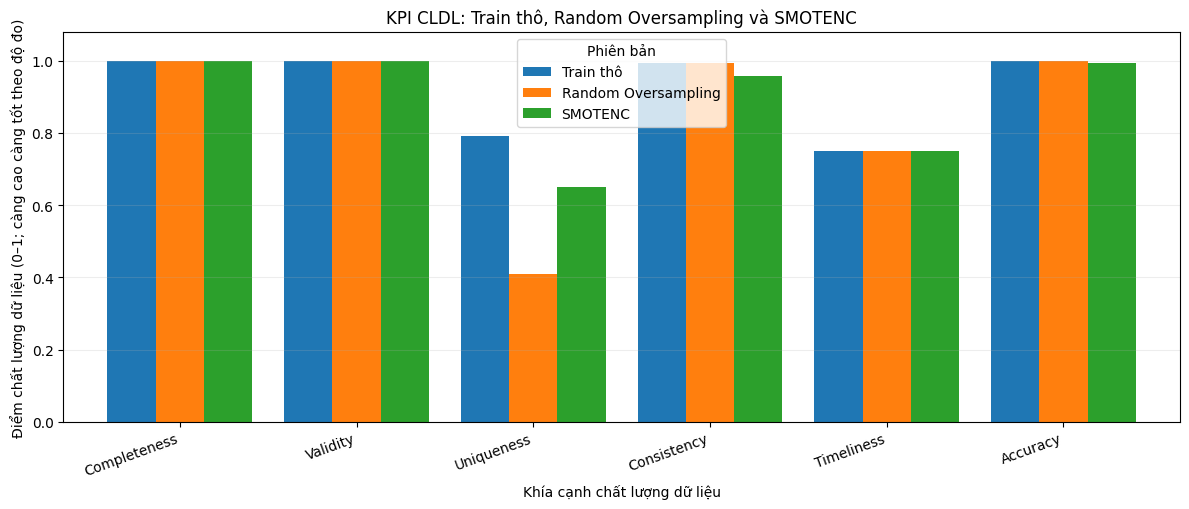

Mốc nền Accuracy phân phối của Train thô so với Test: 0.9991 (99.91%).


In [ ]:
# =====================================================================
# DASHBOARD 1 — KPI TỔNG QUAN (TRAIN THÔ + ROS + SMOTENC)
# =====================================================================
def gate_level(v, soft, hard):
    if pd.isna(v):
        return "N/A"
    return "CRITICAL" if v < hard else ("WARNING" if v < soft else "OK")

def gate_verdict(summary):
    states = [gate_level(summary[d], GATE[d][0], GATE[d][1]) for d in DIM_ORDER]
    worst = max([{"OK": 0, "WARNING": 1, "CRITICAL": 2, "N/A": -1}[x] for x in states])
    return {0: "PASS - cho phép đưa vào huấn luyện",
            1: "PASS CÓ CẢNH BÁO - ghi nhận và theo dõi",
            2: "FAIL - chặn huấn luyện, xử lý nguyên nhân trước",
            -1: "CHƯA ĐỦ DỮ LIỆU ĐỂ KẾT LUẬN"}[worst]

# Thứ tự hiển thị cố định để so sánh trước và sau một cách nhất quán.
CORE_TAGS = [tag for tag in ["Train thô", "Random Oversampling", "SMOTENC"] if tag in RESULTS]
EXPECTED_TAGS = ["Train thô", "Random Oversampling", "SMOTENC"]
missing_tags = [tag for tag in EXPECTED_TAGS if tag not in RESULTS]

print("## Bảng 1. Điểm KPI của sáu khía cạnh — so sánh cùng một bảng")
if not CORE_TAGS:
    print("Chưa có phiên bản dữ liệu nào được nạp thành công.")
else:
    # Mỗi cột là một phiên bản dữ liệu; giá trị được đổi sang phần trăm để dễ đọc.
    score_table = pd.DataFrame({
        "Khía cạnh": DIM_ORDER,
        **{
            f"{tag} (%)": [float(RESULTS[tag]["summary"].reindex(DIM_ORDER)[dim]) * 100
                           for dim in DIM_ORDER]
            for tag in CORE_TAGS
        }
    })
    display(score_table.round(2))

    print("## Bảng 2. Trạng thái cổng chất lượng theo từng phiên bản")
    status_table = pd.DataFrame({
        "Khía cạnh": DIM_ORDER,
        **{
            tag: [gate_level(float(RESULTS[tag]["summary"][dim]), GATE[dim][0], GATE[dim][1])
                  for dim in DIM_ORDER]
            for tag in CORE_TAGS
        }
    })
    display(status_table)

    verdict_table = pd.DataFrame([
        {"Phiên bản": tag, "Kết luận cổng chất lượng": gate_verdict(RESULTS[tag]["summary"])}
        for tag in CORE_TAGS
    ])
    print("### Kết luận tổng thể theo bộ ngưỡng hiện tại")
    display(verdict_table)

    print("## Biểu đồ so sánh sáu khía cạnh")
    plot_data = pd.DataFrame({
        tag: RESULTS[tag]["summary"].reindex(DIM_ORDER).astype(float)
        for tag in CORE_TAGS
    }, index=DIM_ORDER)
    ax = plot_data.plot(kind="bar", figsize=(12, 5.2), width=0.82)
    ax.set_ylabel("Điểm chất lượng dữ liệu (0–1; càng cao càng tốt theo độ đo)")
    ax.set_ylim(0, 1.08)
    ax.set_title("KPI CLDL: Train thô, Random Oversampling và SMOTENC")
    ax.set_xlabel("Khía cạnh chất lượng dữ liệu")
    ax.grid(axis="y", alpha=0.22)
    plt.xticks(rotation=20, ha="right")
    plt.legend(title="Phiên bản", loc="best")
    plt.tight_layout()
    plt.show()

    # Accuracy ở đây là độ trung thực phân phối so với Test, không phải accuracy dự đoán.
    print(f"Mốc nền Accuracy phân phối của Train thô so với Test: {BASE_ACC:.4f} ({BASE_ACC * 100:.2f}%).")

## 6. Chẩn đoán chi tiết — so sánh cả ba phiên bản

Phần này trình bày Train thô, Random Oversampling (ROS) và
SMOTENC trong cùng một lượt chạy.

Các bảng tập trung vào những quy tắc còn vi phạm, Uniqueness,
Timeliness và Accuracy theo độ trung thực phân phối.


In [ ]:
# =====================================================================
# DASHBOARD 2 — CHI TIẾT CẢ 3 PHIÊN BẢN
# =====================================================================
DETAIL_TAGS = [
    tag for tag in
    ["Train thô", "Random Oversampling", "SMOTENC"]
    if tag in RESULTS
]

EXPECTED_DETAIL_TAGS = [
    "Train thô", "Random Oversampling", "SMOTENC"
]

missing_detail_tags = [
    tag for tag in EXPECTED_DETAIL_TAGS
    if tag not in RESULTS
  ]

if missing_detail_tags:
    print(
        "Chưa nạp được một số phiên bản:",
        "; ".join(missing_detail_tags),
        "— hãy kiểm tra đường dẫn CSV."
    )

# 1. Gộp các quy tắc còn vi phạm của cả ba phiên bản
exception_rows = []

for tag in DETAIL_TAGS:
    result = RESULTS[tag]

    rule_to_dim = {
        r.name: r.dimension for r in result["rules"]
    }

    rule_detail = result["rates"].copy()

    rule_detail["Khía cạnh"] = [
        rule_to_dim.get(name, "Không xác định")
        for name in rule_detail.index
    ]

    rule_detail["Số hạt vi phạm"] = (
        (1 - rule_detail["tỷ lệ đạt"])
        * rule_detail["số hạt áp dụng"]
    ).round().astype("Int64")

    rule_detail = rule_detail.reset_index(
        names="Quy tắc"
    )

    exceptions = rule_detail[
        rule_detail["Số hạt vi phạm"].fillna(0) > 0
    ].copy()

    if not exceptions.empty:
        exceptions["Phiên bản"] = tag
        exceptions["tỷ lệ đạt (%)"] = (
            exceptions["tỷ lệ đạt"] * 100
        )

        exception_rows.append(
            exceptions[
                [
                    "Phiên bản",
                    "Khía cạnh",
                    "Quy tắc",
                    "tỷ lệ đạt (%)",
                    "số hạt áp dụng",
                    "Số hạt vi phạm",
                ]
            ]
        )

print("### Quy tắc còn vi phạm — cả ba phiên bản")

if exception_rows:
    all_exceptions = pd.concat(
        exception_rows, ignore_index=True
    )

    display(
        all_exceptions.round(
            {"tỷ lệ đạt (%)": 3}
        )
    )
else:
    print(
        "Không có quy tắc nào ghi nhận vi phạm "
        "ở các phiên bản đã nạp."
    )


# 2. Gộp Uniqueness, Timeliness và Accuracy vào một bảng: mỗi phiên bản một dòng

summary_rows = []

for tag in DETAIL_TAGS:
    data = DATASETS[tag]
    result = RESULTS[tag]

    dup_first = data.duplicated(keep="first")
    dup_all = data.duplicated(keep=False)

    acc_columns = result["acc_table"]

    if not acc_columns.empty:
        weakest = acc_columns.min(axis=1).nsmallest(
            min(3, len(acc_columns))
        )

        weakest_text = ", ".join(
            f"{col}={value:.4f}"
            for col, value in weakest.items()
        )
    else:
        weakest_text = "Không có dữ liệu"

    acc_class = result["acc_class"]

    summary_rows.append({
        "Phiên bản": tag,

        "Uniqueness keep='first' (%)":
            (1 - float(dup_first.mean())) * 100
            if len(data) else np.nan,

        "Uniqueness keep=False (%)":
            (1 - float(dup_all.mean())) * 100
            if len(data) else np.nan,

        "Timeliness (%)":
            float(result["summary"]["Timeliness"]) * 100,

        "Accuracy phân phối (%)":
            float(result["summary"]["Accuracy"]) * 100,

        "Accuracy lớp 0 (%)":
            float(acc_class.get("lớp 0", np.nan)) * 100,

        "Accuracy lớp 1 (%)":
            float(acc_class.get("lớp 1", np.nan)) * 100,

        "3 cột Accuracy thấp nhất": weakest_text,
    })

print(
    "### Tóm tắt Uniqueness, Timeliness và Accuracy "
    "— cả ba phiên bản"
)

summary_table = pd.DataFrame(summary_rows)

display(
    summary_table.round({
        "Uniqueness keep='first' (%)": 3,
        "Uniqueness keep=False (%)": 3,
        "Timeliness (%)": 3,
        "Accuracy phân phối (%)": 3,
        "Accuracy lớp 0 (%)": 3,
        "Accuracy lớp 1 (%)": 3,
    })
)

print(
    "Lưu ý: Accuracy là độ trung thực phân phối so với "
    "Test độc lập, không phải độ chính xác dự đoán mô hình."
)

print(
    "Các quy tắc Validity và Consistency được giữ nguyên; "
    "bảng trên chỉ hiển thị những quy tắc còn vi phạm."
)

### Quy tắc còn vi phạm — cả ba phiên bản


,Phiên bản,Khía cạnh,Quy tắc,tỷ lệ đạt (%),số hạt áp dụng,Số hạt vi phạm
0,Train thô,Uniqueness,toàn bộ thuộc tính·duy nhất,79.270,152568,31627
1,Train thô,Consistency,cùng đặc trưng·cùng nhãn,99.377,120941,754
2,Train thô,Consistency,diabetes chỉ khi mang thai → giới tính nữ,99.572,1403,6
3,Random Oversampling,Uniqueness,toàn bộ thuộc tính·duy nhất,40.811,296344,175403
4,Random Oversampling,Consistency,cùng đặc trưng·cùng nhãn,99.377,120941,754
5,Random Oversampling,Consistency,diabetes chỉ khi mang thai → giới tính nữ,99.572,1403,6
6,SMOTENC,Uniqueness,toàn bộ thuộc tính·duy nhất,64.937,296344,103906
7,SMOTENC,Consistency,cùng đặc trưng·cùng nhãn,95.772,192438,8136
8,SMOTENC,Consistency,diabetes chỉ khi mang thai → giới tính nữ,99.575,1411,6


### Tóm tắt Uniqueness, Timeliness và Accuracy — cả ba phiên bản


,Phiên bản,Uniqueness keep='first' (%),Uniqueness keep=False (%),Timeliness (%),Accuracy phân phối (%),Accuracy lớp 0 (%),Accuracy lớp 1 (%),3 cột Accuracy thấp nhất
0,Train thô,79.270,71.560,75.0,99.906,99.995,99.817,"physical_health_days=0.9898, mental_health_day..."
1,Random Oversampling,40.811,35.370,75.0,99.905,99.995,99.815,"physical_health_days=0.9897, mental_health_day..."
2,SMOTENC,64.937,51.207,75.0,99.419,99.995,98.842,"physical_health_days=0.9491, mental_health_day..."


Lưu ý: Accuracy là độ trung thực phân phối so với Test độc lập, không phải độ chính xác dự đoán mô hình.
Các quy tắc Validity và Consistency được giữ nguyên; bảng trên chỉ hiển thị những quy tắc còn vi phạm.


## 7. Trước / sau can thiệp — SMOTENC và Random Oversampling

Mốc **Trước** là Train thô. Mỗi phương pháp được so sánh với cùng mốc nền và cùng Test tham chiếu. Ngoài 6 điểm CLDL, bảng quy mô hiển thị số dòng, số dòng khác nhau và mức cân bằng lớp để giải thích tác động của resampling.


In [ ]:
# =====================================================================
# DASHBOARD 3 — SO SÁNH TRƯỚC / SAU CÁC CAN THIỆP CHÍNH
# =====================================================================
CORE_TAGS = [tag for tag in ["Train thô", "SMOTENC", "Random Oversampling"] if tag in RESULTS]
comparison = pd.DataFrame({tag: RESULTS[tag]["summary"] for tag in CORE_TAGS}).T
comparison.index.name = "Phiên bản"

if "Train thô" in comparison.index:
    delta_table = comparison.subtract(comparison.loc["Train thô"], axis=1)
    delta_table.index.name = "Phiên bản"
    print("### Mức thay đổi so với Train thô (Δ = Sau − Trước)")
    display(delta_table.round(4))

# Thống kê quy mô/balance của từng phiên bản
balance_rows = []
ref_counts = ref[LABEL].value_counts().sort_index()
minority_label = ref_counts.idxmin()
for tag in CORE_TAGS:
    d = DATASETS[tag]
    counts = d[LABEL].value_counts().sort_index()
    p = counts / len(d)
    balance_rows.append({
        "Phiên bản": tag,
        "Số dòng": len(d),
        "Số dòng khác nhau": len(d.drop_duplicates()),
        "Số dòng lặp sau lần đầu": int(d.duplicated(keep="first").sum()),
        f"Số mẫu lớp thiểu số ({minority_label})": int(counts.get(minority_label, 0)),
        "Tỷ lệ lớp thiểu số (%)": float(p.get(minority_label, 0) * 100),
        "Chỉ số cân bằng lớp": float(1 - abs(p.max() - p.min())),
    })
print("### Quy mô, trùng lặp và cân bằng lớp")
display(pd.DataFrame(balance_rows).round(4))


### Mức thay đổi so với Train thô (Δ = Sau − Trước)


,Completeness,Validity,Uniqueness,Consistency,Timeliness,Accuracy
Phiên bản,,,,,,
Train thô,0.0,0.0,0.0000,0.000,0.0,0.0000
SMOTENC,0.0,0.0,-0.1433,-0.036,0.0,-0.0049
Random Oversampling,0.0,0.0,-0.3846,0.000,0.0,-0.0000


### Quy mô, trùng lặp và cân bằng lớp


,Phiên bản,Số dòng,Số dòng khác nhau,Số dòng lặp sau lần đầu,Số mẫu lớp thiểu số (1),Tỷ lệ lớp thiểu số (%),Chỉ số cân bằng lớp
0,Train thô,152568,120941,31627,4396,2.8813,0.0576
1,SMOTENC,296344,192438,103906,148172,50.0000,1.0000
2,Random Oversampling,296344,120941,175403,148172,50.0000,1.0000


## 8. Thí nghiệm phụ — điền khuyết và làm giàu (tách riêng)

Chỉ để xem xét nhưng không dùng đến!

In [ ]:
# =====================================================================
# DASHBOARD 4 — KẾT QUẢ PHỤ
# =====================================================================
OPTIONAL_TAGS = ["Điền khuyết (TÙY CHỌN)", "Làm giàu (TÙY CHỌN)"]
optional_available = [tag for tag in OPTIONAL_TAGS if tag in RESULTS]

if optional_available:
    optional_rows = []
    for tag in optional_available:
        for dim in DIM_ORDER:
            val = float(RESULTS[tag]["summary"][dim])
            base = float(RESULTS["Train thô"]["summary"][dim])
            optional_rows.append({"Phương pháp phụ": tag, "Khía cạnh": dim,
                                 "Trước — Train thô": base, "Sau": val, "Δ": val - base})
    optional_table = pd.DataFrame(optional_rows)
    display(optional_table.round(4))
    for tag in optional_available:
        print(f"\n### Chi tiết riêng: {tag}")
        display(pd.DataFrame({"Điểm": RESULTS[tag]["summary"],
                              "Số hạt": pd.Series(RESULTS[tag]["n_grains"]).reindex(DIM_ORDER)}).round(4))
else:
    print("Chưa chạy điền khuyết hoặc làm giàu — đúng theo trạng thái thí nghiệm phụ.")
    print("Khi muốn thử, đặt X_IMPUTED_PATH/Y_IMPUTED_PATH hoặc X_ENRICHED_PATH/Y_ENRICHED_PATH trong phần Cấu hình.")

print("\nGhi chú báo cáo: chỉ đưa điền khuyết/làm giàu vào kết luận chính sau khi xem bảng riêng này và xác nhận tính hợp lệ của dữ liệu tham chiếu.")


## 9. Lưu các bảng phục vụ báo cáo

Lưu kết quả theo từng phiên bản đã nạp, bảng so sánh tổng hợp, hồ sơ chất lượng (DQP) và biểu đồ KPI. Đường dẫn xuất mặc định là thư mục làm việc hiện tại của notebook.


In [ ]:
# =====================================================================
# BƯỚC CUỐI — XUẤT CSV, JSON VÀ HÌNH KPI
# =====================================================================
export_rows = []
for tag, result in RESULTS.items():
    safe_tag = re.sub(r"[^A-Za-z0-9_-]+", "_", tag).strip("_")
    dim_summary = result["summary"].reindex(DIM_ORDER)
    store = pd.DataFrame({
        "run": tag,
        "table": "stroke",
        "dimension": DIM_ORDER,
        "value": dim_summary.values,
        "n_grains": [result["n_grains"].get(d, 0) for d in DIM_ORDER],
    })
    store.to_csv(f"metric_store_{safe_tag}.csv", index=False)
    export_rows.append(store)

    gate = pd.DataFrame([{
        "Khía cạnh": dim,
        "Giá trị": float(dim_summary[dim]),
        "Ngưỡng mềm": GATE[dim][0],
        "Ngưỡng cứng": GATE[dim][1],
        "Hành động nếu vi phạm": GATE[dim][2],
        "Trạng thái": gate_level(dim_summary[dim], GATE[dim][0], GATE[dim][1]),
    } for dim in DIM_ORDER])
    verdict = gate_verdict(dim_summary)
    dqp = {
        "dataset": f"stroke_{safe_tag}",
        "measured_at": str(pd.Timestamp.today().date()),
        "n_records": int(len(DATASETS[tag])),
        "dimensions": {k: round(float(v), 4) for k, v in dim_summary.items()},
        "gate": verdict,
        "rules_below_100pct": {
            k: round(float(v), 5)
            for k, v in result["rates"]["tỷ lệ đạt"].dropna().items()
            if v < 1
        },
        "accuracy_baseline_train_vs_test": round(float(BASE_ACC), 4),
        "convention": {
            "aggregation": "grain_mean (TEMPO-DQ)",
            "uniqueness": "keep='first'",
            "consistency_grain": "bản ghi khác nhau",
            "validity_ranges": FIXED_RANGES,
            "timeliness": f"Pipino currency={CURRENCY_YEARS}, volatility={VOLATILITY_YEARS}, s={S_EXP}",
            "accuracy": "độ trung thực phân phối thuộc tính theo từng lớp so với Test, trung bình các lớp",
        },
    }
    with open(f"dqp_{safe_tag}.json", "w", encoding="utf-8") as f:
        json.dump(dqp, f, ensure_ascii=False, indent=2)

    fig, ax = plt.subplots(figsize=(8, 3.8))
    vals = dim_summary
    ax.barh(DIM_ORDER, vals.values, height=0.55)
    for i, dim in enumerate(DIM_ORDER):
        v = float(vals[dim])
        ax.text(min(v + 0.01, 1.0), i, f"{v:.4f}", va="center", fontsize=9)
        soft, hard, _ = GATE[dim]
        ax.plot([soft, soft], [i - 0.35, i + 0.35], lw=2, linestyle="--")
        ax.plot([hard, hard], [i - 0.35, i + 0.35], lw=2, linestyle=":")
    ax.invert_yaxis()
    ax.set_xlim(0, 1.12)
    ax.set_xlabel("Giá trị độ đo")
    ax.set_title(f"Sáu khía cạnh CLDL — {tag}")
    ax.grid(axis="x", alpha=0.2)
    plt.tight_layout()
    fig.savefig(f"dq_6_khia_canh_{safe_tag}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)

if export_rows:
    pd.concat(export_rows, ignore_index=True).to_csv("dq_comparison_all.csv", index=False)

print("Đã xuất hồ sơ theo phiên bản:")
for tag in RESULTS:
    safe_tag = re.sub(r"[^A-Za-z0-9_-]+", "_", tag).strip("_")
    print(f"- metric_store_{safe_tag}.csv | dqp_{safe_tag}.json | dq_6_khia_canh_{safe_tag}.png")
print("- dq_comparison_all.csv")


Đã xuất hồ sơ theo phiên bản:
- metric_store_Train_th.csv | dqp_Train_th.json | dq_6_khia_canh_Train_th.png
- metric_store_SMOTENC.csv | dqp_SMOTENC.json | dq_6_khia_canh_SMOTENC.png
- metric_store_Random_Oversampling.csv | dqp_Random_Oversampling.json | dq_6_khia_canh_Random_Oversampling.png
- dq_comparison_all.csv
